
<div style="font-family:Arial; color:#1e293b; line-height:1.6;">

<div style="background:linear-gradient(135deg,#123c69,#2563eb);
color:white; padding:25px; border-radius:14px;">
    <h1 style="color:white;">CBIM Problem Canvas</h1>
    <h3 style="color:#dbeafe;">Category Intelligence – Retail Product Performance</h3>
</div>

<div style="background:#e0f2fe; border-left:6px solid #0284c7;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#075985;"> 1. Situation</h2>
    <p>A retail chain operates 12 stores across Andhra Pradesh and sells
    products across five categories. The Category Manager is preparing
    for the upcoming quarterly supplier review.</p>
</div>

<div style="background:#fff7ed; border-left:6px solid #f97316;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#9a3412;"> 2. Complication</h2>
    <p>The manager needs to identify strong and weak categories, understand
    product revenue differences, and evaluate discount effectiveness
    before making supplier-related decisions.</p>
</div>

<div style="background:#f3e8ff; border-left:6px solid #9333ea;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#6b21a8;"> 3. Key Business Question</h2>
    <p><b>Which categories should the Category Manager prioritise or
    challenge during the supplier review, based on six-month revenue
    performance and discount effectiveness?</b></p>
</div>

<div style="background:#dcfce7; border-left:6px solid #16a34a;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#166534;"> 4. SSOT – Single Source of Truth</h2>
    <p>The team will use MUC01_Retail_Sales_Dataset.csv as the common
    source of data. All team members will use consistent calculations
    to analyse revenue, categories, products, months, and discounts.</p>
</div>

<div style="background:#fce7f3; border-left:6px solid #db2777;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#9d174d;"> 5. Success Definition</h2>
    <ul>
        <li>Identify the highest- and lowest-performing categories.</li>
        <li>Compare monthly revenue trends across categories.</li>
        <li>Find the top two and bottom two products in each category.</li>
        <li>Compare average revenue per transaction by discount bracket.</li>
        <li>Provide evidence-based supplier review recommendations.</li>
    </ul>
</div>

<div style="background:#fef9c3; border-left:6px solid #ca8a04;
padding:16px; margin-top:15px; border-radius:8px;">
    <h2 style="color:#854d0e;"> 6. Stakeholders</h2>
    <p><b>Primary stakeholder:</b> Category Manager</p>
    <p><b>Other stakeholders:</b> Suppliers, store management, and the
    retail analysis team.</p>
    <p><b>Decision:</b> Identify which categories and suppliers need
    attention based on sales evidence.</p>
</div>

<div style="background:#0f172a; color:white; padding:20px;
margin-top:15px; border-radius:12px;">
    <h2 style="color:#93c5fd;">📌 Expected Outcome</h2>
    <p>A concise, data-driven briefing explaining category performance,
    revenue trends, discount patterns, limitations, and practical
    recommendations for the Category Manager.</p>
</div>

</div>


In [ ]:
import pandas as pd

<h2 style="color:#2563eb;"> 1. Load the Dataset</h2>
<p>Import the retail sales dataset using Pandas.</p>

In [ ]:
from pathlib import Path
import pandas as pd

# Find the dataset in the notebook folder or its common project subfolder.
candidates = [
    Path("MUC01_Retail_Sales_Dataset.csv"),
    Path("Retail_Sales_Dataset.csv"),
    Path("CBIM-Retail-Product-Analysis") / "MUC01_Retail_Sales_Dataset.csv",
    Path("CBIM-Retail-Product-Analysis") / "Retail_Sales_Dataset.csv",
]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "CSV file not found. Put MUC01_Retail_Sales_Dataset.csv "
        "or Retail_Sales_Dataset.csv in the same folder as this notebook."
    )

df = pd.read_csv(csv_path)
print("Loaded dataset:", csv_path.resolve())
print(df)


<h2 style="color:#16a34a;"> 2. Display First Five Rows</h2>
<p>Display the first five rows to understand the structure and contents of the dataset.</p>

In [17]:
display(df.head())

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0


<h2 style="color:#9333ea;"> 3. Check Dataset Shape</h2>
<p>Find the total number of rows and columns in the dataset.</p>

In [12]:
print("Number of rows and columns:")
display(df.shape)
print("Total rows:")
display(df.shape[0])
print("Total columns:")
display(df.shape[1])

Number of rows and columns:


(107836, 10)

Total rows:


107836

Total columns:


10

<h2 style="color:#ea580c;"> 4. Check Data Types</h2>
<p>Inspect the column names, data types, and non-null values.</p>

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107836 entries, 0 to 107835
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   transaction_id  107836 non-null  object 
 1   date            107836 non-null  object 
 2   store_id        107836 non-null  object 
 3   store_city      107836 non-null  object 
 4   category        107836 non-null  object 
 5   product_name    107836 non-null  object 
 6   units_sold      107836 non-null  int64  
 7   unit_price      107836 non-null  float64
 8   revenue         107836 non-null  float64
 9   discount_pct    107836 non-null  int64  
dtypes: float64(2), int64(2), object(6)
memory usage: 8.2+ MB


<h2 style="color:#dc2626;"> 5. Check Missing Values</h2>
<p>Identify the number of missing values in each column.</p>

In [14]:
print("Missing values in each column:")
display(df.isnull().sum())

Missing values in each column:


transaction_id    0
date              0
store_id          0
store_city        0
category          0
product_name      0
units_sold        0
unit_price        0
revenue           0
discount_pct      0
dtype: int64

<h2 style="color:#ca8a04;"> 6. Descriptive Statistics</h2>
<p>Summarise the dataset to understand its numerical values and distributions.</p>

In [15]:
display(df.describe(include="all"))

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
count,107836,107836,107836,107836,107836,107836,107836.000000,107836.000000,107836.000000,107836.000000
unique,107836,181,12,6,5,25,NaN,NaN,NaN,NaN
top,TXN107836,2026-06-20,S01,Vijayawada,Grocery,Rice (5kg),NaN,NaN,NaN,NaN
freq,1,859,13270,23083,54185,10971,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.583488,1778.097787,4263.920924,7.228152
std,NaN,NaN,NaN,NaN,NaN,NaN,1.471616,5053.631792,14243.244169,6.730445
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,50.020000,40.040000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,274.827500,467.772500,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,488.450000,1034.615000,5.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,1039.522500,2473.335000,10.000000


<div style="background:#f3e8ff; padding:18px; border-left:6px solid#7c3aed; border-radius:10px;">
<h2 style="color:#6d28d9;"> 7. Business Observations</h2>
<p style="color:#374151;">Analyse the dataset results and identify two important business observations.</p>
</div>

In [16]:
# Count unique products and categories
print("Unique Products:", df["product_name"].nunique())
print("Unique Categories:", df["category"].nunique())

# Two Business Observations
print("\nBusiness Observations:")
print("1. Counting unique products helps understand the variety of products available")
print("2. Counting unique categories helps compare product groups and analyse category-wise performance")

Unique Products: 25
Unique Categories: 5

Business Observations:
1. Counting unique products helps understand the variety of products available
2. Counting unique categories helps compare product groups and analyse category-wise performance


### 1.We count unique products to understand the variety of products available 
### 2.We count unique categories to understand how products are grouped for business analysis

## Step 5.2 — Monthly Revenue Analysis

**Objective:** Analyse monthly revenue trends across the five product categories, identify the category with the steepest decline, and determine which category has the most consistent revenue.

In [ ]:
from pathlib import Path
import pandas as pd

# Find the dataset in the notebook folder or its common project subfolder.
candidates = [
    Path("MUC01_Retail_Sales_Dataset.csv"),
    Path("Retail_Sales_Dataset.csv"),
    Path("CBIM-Retail-Product-Analysis") / "MUC01_Retail_Sales_Dataset.csv",
    Path("CBIM-Retail-Product-Analysis") / "Retail_Sales_Dataset.csv",
]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "CSV file not found. Put MUC01_Retail_Sales_Dataset.csv "
        "or Retail_Sales_Dataset.csv in the same folder as this notebook."
    )

df = pd.read_csv(csv_path)
print("Loaded dataset:", csv_path.resolve())
print(df)


### 5.2.1 Check the dataset columns

In [36]:
print(df.columns.tolist())
display(df.head())


['transaction_id', 'date', 'store_id', 'store_city', 'category', 'product_name', 'units_sold', 'unit_price', 'revenue', 'discount_pct']


,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0


### Explanation

In this step, we inspect the dataset to understand its structure. We display all column names and the first five rows to identify the columns containing transaction dates, product categories, and revenue. These columns are required to perform the monthly revenue analysis.

### 2. Select the required columns

In [37]:
# Select the correct columns from our dataset
DATE_COL = "date"
CATEGORY_COL = "category"
REVENUE_COL = "revenue"

print("Date column:", DATE_COL)
print("Category column:", CATEGORY_COL)
print("Revenue column:", REVENUE_COL)

Date column: date
Category column: category
Revenue column: revenue


### Explanation

In this step, we select the date, category, and revenue columns from the dataset. These columns are essential for analysing monthly revenue across product categories. The column names must match the dataset exactly, including lowercase and uppercase letters.

###  5.2.2 Calculate monthly revenue by category

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert dates and revenue into the correct data formats
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[REVENUE_COL] = pd.to_numeric(df[REVENUE_COL], errors="coerce")

# Remove rows with missing values in the required columns
analysis_df = df.dropna(subset=[DATE_COL, CATEGORY_COL, REVENUE_COL]).copy()

# Extract the month from each transaction date
analysis_df["Month"] = (analysis_df[DATE_COL].dt.to_period("M").dt.to_timestamp())

# Calculate total revenue for each category in each month
monthly_revenue = analysis_df.pivot_table(
    index="Month",
    columns=CATEGORY_COL,
    values=REVENUE_COL,
    aggfunc="sum").sort_index()

# Display the monthly revenue table
display(monthly_revenue)

category,Apparel,Electronics,Grocery,Home & Kitchen,Personal Care
Month,,,,,
2026-01-01,10049916.78,45686596.63,7307011.34,15130871.54,6593734.81
2026-02-01,9510938.10,38988602.50,6534957.35,13006413.31,5792754.97
2026-03-01,11540439.47,40846509.47,7132787.06,14362119.50,6808029.34
2026-04-01,11681806.66,37092265.09,7047399.58,13431147.66,6417868.13
2026-05-01,13219535.79,34226926.43,7232706.20,13581886.25,7298818.71
2026-06-01,13476952.88,29686824.81,7047719.23,12333283.07,6737354.12


### Explanation

In this step, we prepare the dataset and calculate monthly revenue for each product category. We convert the date and revenue columns into suitable formats and remove records with missing values in the required fields.

We then create a Month column and use a pivot table to sum revenue for each category in each month. This table helps us compare category performance over time and identify changes in monthly revenue.

### 5.2.3 Monthly Revenue Trend Visualization

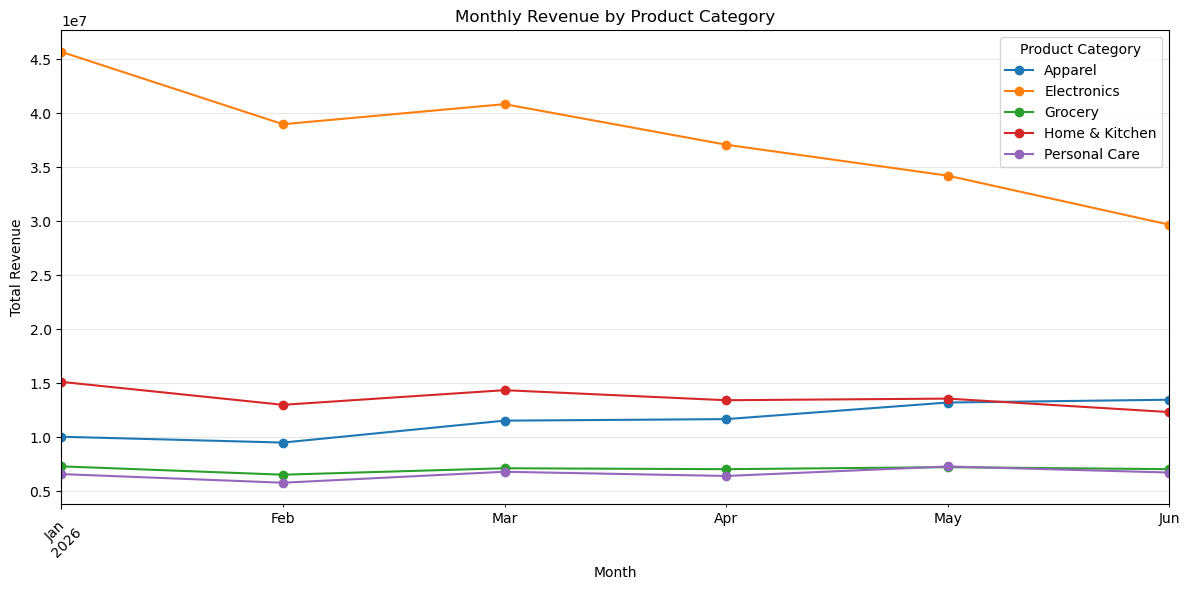

In [39]:
# Plot monthly revenue trends for all categories
monthly_revenue.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Revenue by Product Category")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Explanation

In this step, we create a line chart to compare monthly revenue across product categories. Each line represents a category. An upward line indicates increasing revenue, while a downward line indicates decreasing revenue. A relatively flat line indicates more stable revenue.

The chart helps us identify trends and categories that may require further investigation.

### 5.2.4 Find the biggest revenue decline

In [40]:
monthly_change = monthly_revenue.diff()

biggest_drop = monthly_change.min().idxmin()
biggest_drop_value = monthly_change.min().min()

print("Category with the biggest revenue drop:", biggest_drop)
print("Revenue change:", biggest_drop_value)

Category with the biggest revenue drop: Electronics
Revenue change: -6697994.130000003


### Explanation

In this step, we calculate how revenue changes from one month to the next. Negative values represent decreases in revenue. We identify the category with the largest absolute month-to-month decrease.

This helps the Category Manager identify categories that may need investigation into customer demand, product availability, or promotional activities.

### Step 5.2.5  Finding the most consistent categor

In [41]:
# Measure monthly revenue variation for each category
variability = monthly_revenue.std()

# Find the category with the lowest variation
consistent_category = variability.idxmin()

print("Most consistent category:", consistent_category)
print("Standard deviation:", variability[consistent_category])

Most consistent category: Grocery
Standard deviation: 272605.89394647174


### Explanation

In this step, we use standard deviation to measure how much monthly revenue varies for each category. A lower standard deviation indicates less variation in revenue. The category with the lowest standard deviation is identified as the most consistent based on its absolute revenue variation.

This information can support monthly planning, although categories with lower overall revenue may also have lower variation.

#### The analysis results

In [42]:
# Calculate month-to-month revenue changes
monthly_change = monthly_revenue.diff()
category_drops = monthly_change.min()

biggest_drop = category_drops.idxmin()
biggest_drop_value = category_drops.min()

variability = monthly_revenue.std()
consistent_category = variability.idxmin()
print("Category with the biggest revenue decline:", biggest_drop)
print("Largest revenue decrease:", biggest_drop_value)

print("\nMost consistent category:", consistent_category)
print("Standard deviation:", variability[consistent_category])

Category with the biggest revenue decline: Electronics
Largest revenue decrease: -6697994.130000003

Most consistent category: Grocery
Standard deviation: 272605.89394647174


### Explanation

This step identifies the category with the largest month-to-month revenue decrease and the category with the most consistent monthly revenue. We calculate the change in revenue between consecutive months and use the minimum change to identify the steepest absolute decline. We then calculate the standard deviation of monthly revenue for each category. The category with the lowest standard deviation has the least variation in revenue.

These results help the Category Manager identify categories that may require attention and categories with more stable revenue patterns.

### Step 5.2.6 — Business Observations

**1. Category with the steepest revenue decline**

Electronics experienced the largest month-to-month revenue decrease of approximately 6,697,994.13. This significant decline suggests that the category may have experienced a substantial change in sales performance during one month. The Category Manager should investigate possible causes, such as changes in customer demand, product availability, pricing, or promotional activities.

**2. Category with the most consistent revenue**

Grocery was identified as the most consistent category, with a monthly revenue standard deviation of approximately 272,605.89. This indicates that Grocery had the lowest variation in absolute monthly revenue among the categories analysed.

**3. Business recommendation**

The Category Manager should investigate the month in which Electronics experienced its largest revenue decline and identify the possible reasons. Grocery's more stable revenue pattern can also be considered when planning inventory and monitoring monthly category performance.

### Summary of Monthly Revenue Analysis

This analysis examines monthly revenue across product categories using a summary table and a line chart. Month-to-month revenue changes are used to identify the category with the largest revenue decline, while standard deviation is used to identify the category with the most consistent revenue. The findings help the Category Manager understand category performance, investigate significant declines, and make more informed decisions about inventory and promotions.

### Step 5.3 — Top and Bottom Product Performance by Category

### 5.3.1 Objective

The objective of this analysis is to identify the top two and bottom two products by total revenue within each product category. This helps us understand which products contribute the most and least revenue and supports product-level business decisions.

### 5.3.2 — Product Revenue Calculation

In [43]:
# Calculate total revenue for each product within each category
product_revenue = (
    df.groupby(["category", "product_name"], as_index=False)["revenue"]
    .sum()
)

# Display the first five rows of the result
display(product_revenue.head())

,category,product_name,revenue
0,Apparel,Formal Shirt,13748976.91
1,Apparel,Jeans,13862749.46
2,Apparel,Kurta,13606747.03
3,Apparel,Saree,14161864.63
4,Apparel,T-Shirt,14099251.65


###  explanation: 

In this step, we group the dataset by product category and product name. We calculate the sum of revenue generated by each product. This produces a table showing the total revenue for each product within its category and provides the information needed to rank products by performance.

 ### 5.3.3 — Top 2 and Bottom 2 Products

In [44]:
# Sort products within each category from highest to lowest revenue
product_revenue_sorted = product_revenue.sort_values(
    ["category", "revenue"],
    ascending=[True, False]
)

# Select the two highest-revenue products in each category
top_products = (
    product_revenue_sorted.groupby("category")
    .head(2)
    .copy()
)
top_products["Performance"] = "Top 2"

# Select the two lowest-revenue products in each category
bottom_products = (
    product_revenue_sorted.groupby("category")
    .tail(2)
    .copy()
)
bottom_products["Performance"] = "Bottom 2"

# Combine the top and bottom products into one table
product_summary = pd.concat(
    [top_products, bottom_products],
    ignore_index=True
)

# Arrange the results for easier reading
product_summary = product_summary.sort_values(
    ["category", "Performance", "revenue"],
    ascending=[True, True, False]
)

display(product_summary)

,category,product_name,revenue,Performance
10,Apparel,Formal Shirt,13748976.91,Bottom 2
11,Apparel,Kurta,13606747.03,Bottom 2
0,Apparel,Saree,14161864.63,Top 2
1,Apparel,T-Shirt,14099251.65,Top 2
12,Electronics,Tablet,44744388.93,Bottom 2
13,Electronics,Smart TV,41882166.21,Bottom 2
2,Electronics,Headphones,47696053.99,Top 2
3,Electronics,Laptop,46551078.39,Top 2
14,Grocery,Oil (1L),8431630.01,Bottom 2
15,Grocery,Sugar (1kg),8377786.05,Bottom 2


 ### Explanation: 

In this step, we rank products according to their total revenue within each category. The two products with the highest revenue are classified as the top-performing products, while the two products with the lowest revenue are classified as the bottom-performing products. We combine these results into one table to make product comparisons easier.

If a category has fewer than four distinct products, the top and bottom groups may overlap.

### 5.3.4 Summary Table

The summary table presents the top two and bottom two products by total revenue for each product category. It includes the product category, product name, total revenue, and performance group. This table provides a clear comparison of high- and low-revenue products within each category.

### 5.3.5 Business Insights and Recommendations

1. **Top-performing products:** The top two products in each category generated the highest total revenue among the products in that category. Their performance should be monitored to support product availability and continued sales.

2. **Lowest-performing products:** The bottom two products generated the lowest total revenue in their respective categories. Their performance should be investigated to understand possible reasons for lower revenue.

3. **Business recommendation:** The Category Manager should use product-level revenue results to support inventory planning and promotional decisions. Revenue alone does not indicate profitability, so costs, sales volume, and stock availability should also be considered before making business decisions.

### 5.3.6 Conclusion

This analysis identifies the top two and bottom two products by total revenue within each product category. The results help us understand which products contribute the most and least revenue. The business can use these findings to improve inventory planning, review low-performing products, and make better product promotion decisions. Further analysis of product costs, units sold, and profit would provide a more complete understanding of product performance.

## Step 5.4 — Discount Effectiveness Analysis

This analysis examines how different discount levels relate to average revenue per transaction and average units sold. The results will help the Category Manager assess whether higher discounts are associated with stronger sales and whether the additional revenue may justify the discounts offered.

### 5.4.1 Objective

The objective is to compare transactions across six discount brackets: 0%, 5%, 10%, 15%, 20%, and 25% or more. For each bracket, we will calculate average revenue per transaction and average units sold, then use a bar chart to compare average revenue. This will help us evaluate the relationship between discount levels and sales performance.

#### Prepare and group the data

In [45]:

# Create discount brackets for the analysis
discount_bins = [-0.01, 0, 5, 10, 15, 20, float("inf")]
discount_labels = ["0%", "5%", "10%", "15%", "20%", "25%+"]

# Assign each transaction to a discount bracket
df["discount_bracket"] = pd.cut(
    df["discount_pct"],
    bins=discount_bins,
    labels=discount_labels,
    right=True
)

# Calculate average revenue and average units sold for each bracket
discount_summary = (
    df.groupby("discount_bracket", observed=False)
    .agg(
        avg_revenue_per_transaction=("revenue", "mean"),
        avg_units_sold=("units_sold", "mean"),
        transaction_count=("transaction_id", "count")
    )
    .reset_index()
)

# Display the results
display(discount_summary.round(2))


,discount_bracket,avg_revenue_per_transaction,avg_units_sold,transaction_count
0,0%,4685.65,2.59,36033
1,5%,4303.73,2.59,23922
2,10%,4005.55,2.57,23810
3,15%,4069.16,2.60,11935
4,20%,3631.73,2.58,12136
5,25%+,NaN,NaN,0


 #### 5.4.2 — Check the discount values

In [46]:
# Check the discount values present in the dataset
print("Discount values found in the data:")
print(sorted(df["discount_pct"].dropna().unique()))

print("\nMinimum discount:", df["discount_pct"].min())
print("Maximum discount:", df["discount_pct"].max())


Discount values found in the data:
[np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20)]

Minimum discount: 0
Maximum discount: 20


#### 5.4.3 — Create the bar chart

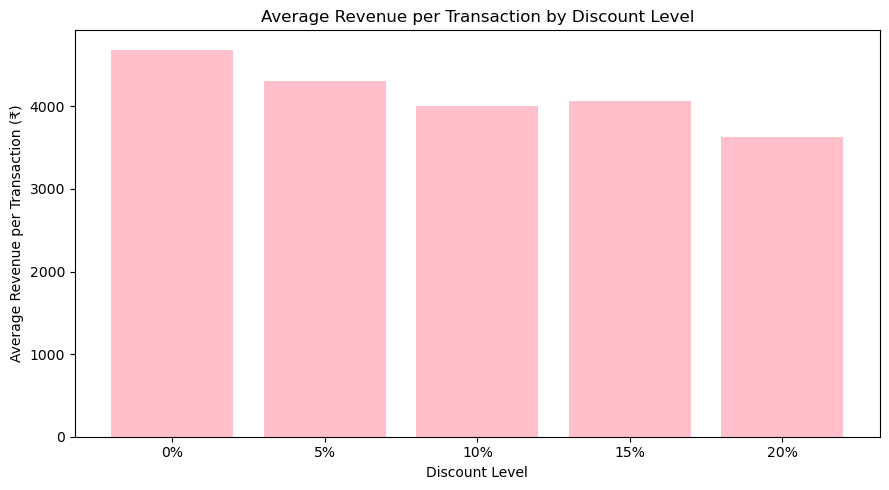

In [64]:
import matplotlib.pyplot as plt

# Prepare data for the chart, excluding brackets with no transactions
chart_data = discount_summary.dropna(
    subset=["avg_revenue_per_transaction"]
)

# Plot average revenue per transaction by discount bracket
plt.figure(figsize=(9, 5))
plt.bar(
    chart_data["discount_bracket"].astype(str),
    chart_data["avg_revenue_per_transaction"],color = "pink"
    
)

plt.title("Average Revenue per Transaction by Discount Level")
plt.xlabel("Discount Level")
plt.ylabel("Average Revenue per Transaction (₹)")
plt.tight_layout()
plt.show()


### 5.4.4 Business Insights and Recommendations

The results suggest that higher discounts are not generating higher average revenue per transaction. Transactions with no discount have the highest average revenue of ₹4,685.65, while transactions with a 20% discount average ₹3,631.73. This is a decrease of approximately 22.5% in average revenue per transaction. Meanwhile, average units sold remain almost unchanged, ranging from 2.57 to 2.60 units across the discount levels.

From the Category Manager's perspective, this suggests that the current discount strategy may not be delivering a proportionate increase in transaction value. The business should review whether discounts are necessary at higher levels and consider targeted promotions instead of broad discounts. However, average revenue alone cannot establish whether discounts reduce profit, because product costs, margins, and customer purchasing behaviour have not been analysed. The dataset contains no transactions at 25% or above, so no conclusion can be drawn about that discount range.

## Step 5.5 — Day-of-Week and Monthly Patterns

This analysis examines how revenue varies by day of the week and by month. It identifies the strongest and weakest periods for the retail chain and compares the overall pattern with Electronics, the category that showed the steepest revenue decline in Step 5.2. These findings can help the Category Manager choose more effective timings for promotions and supplier discussions.

#### The date information

In [55]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove rows with invalid dates or missing revenue
time_df = df.dropna(subset=["date", "revenue"]).copy()

# Extract weekday and month information
time_df["day_of_week"] = time_df["date"].dt.day_name()
time_df["month"] = time_df["date"].dt.to_period("M")

# Set weekday order for charts
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

print("Date range:", time_df["date"].min().date(), "to",
      time_df["date"].max().date())
print("Rows available for analysis:", len(time_df))


Date range: 2026-01-01 to 2026-06-30
Rows available for analysis: 107836


### Average daily revenue by day of the week

Best day: Saturday — Average revenue: ₹ 3523605.44
Worst day: Monday — Average revenue: ₹ 2012140.96


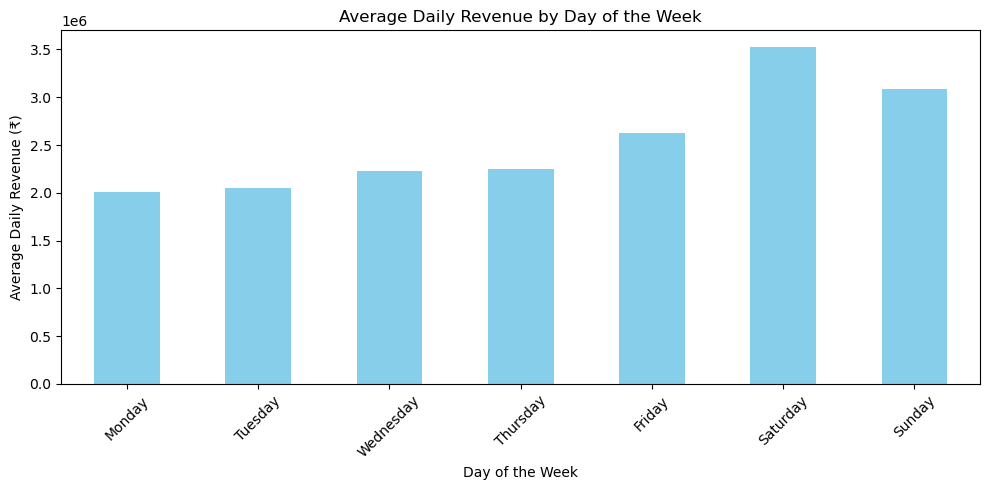

In [63]:

# First calculate total revenue for each calendar date
daily_revenue = (
    time_df.groupby("date", as_index=False)["revenue"]
    .sum()
)

daily_revenue["day_of_week"] = daily_revenue["date"].dt.day_name()

# Calculate average daily revenue for each weekday
weekday_revenue = (
    daily_revenue.groupby("day_of_week")["revenue"]
    .mean()
    .reindex(weekday_order)
)

# Identify the strongest and weakest weekdays
print("Best day:", weekday_revenue.idxmax(),
      "— Average revenue: ₹", round(weekday_revenue.max(), 2))
print("Worst day:", weekday_revenue.idxmin(),
      "— Average revenue: ₹", round(weekday_revenue.min(), 2))

# Plot the weekday pattern
plt.figure(figsize=(10, 5))
weekday_revenue.plot(kind="bar", color= "skyblue")
plt.title("Average Daily Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Daily Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


   #### Total revenue by month

Best month: 2026-01 — Total revenue: ₹ 84768131.1
Worst month: 2026-06 — Total revenue: ₹ 69282134.11


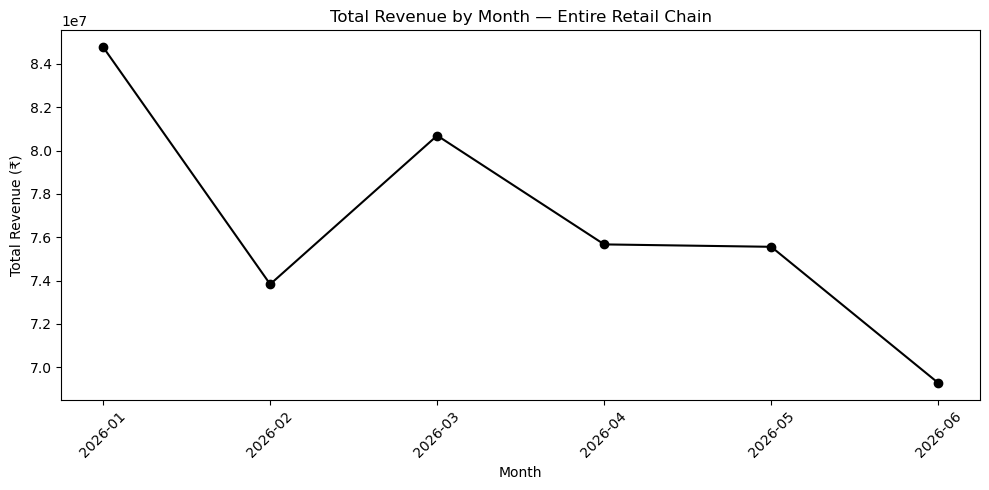

In [67]:

# Calculate total revenue for each month across the chain
monthly_revenue = (
    time_df.groupby("month")["revenue"]
    .sum()
    .sort_index()
)

print("Best month:", monthly_revenue.idxmax(),
      "— Total revenue: ₹", round(monthly_revenue.max(), 2))
print("Worst month:", monthly_revenue.idxmin(),
      "— Total revenue: ₹", round(monthly_revenue.min(), 2))

# Plot monthly revenue
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",color = "black"
)
plt.title("Total Revenue by Month — Entire Retail Chain")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Compare Electronics with the whole chain

ELECTRONICS
Best day: Saturday — Average revenue: ₹ 1786658.45
Worst day: Monday — Average revenue: ₹ 970975.52
Best month: 2026-01 — Total revenue: ₹ 45686596.63
Worst month: 2026-06 — Total revenue: ₹ 29686824.81


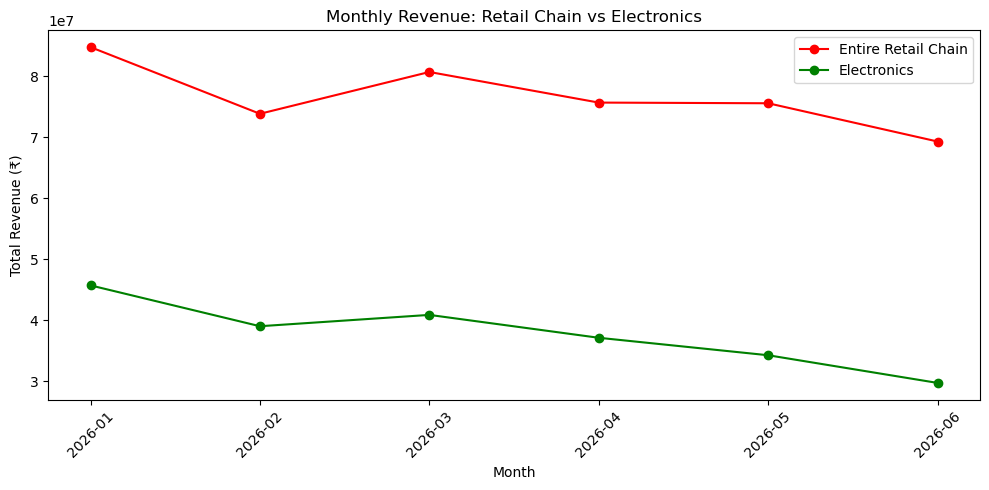

In [73]:

# Calculate average daily revenue for Electronics by weekday
electronics_df = time_df[
    time_df["category"] == "Electronics"
].copy()

electronics_daily = (
    electronics_df.groupby("date", as_index=False)["revenue"]
    .sum()
)

electronics_daily["day_of_week"] = (
    electronics_daily["date"].dt.day_name()
)

electronics_weekday = (
    electronics_daily.groupby("day_of_week")["revenue"]
    .mean()
    .reindex(weekday_order)
)

# Calculate total monthly revenue for Electronics
electronics_monthly = (
    electronics_df.groupby("month")["revenue"]
    .sum()
    .sort_index()
)

print("ELECTRONICS")
print("Best day:", electronics_weekday.idxmax(),
      "— Average revenue: ₹", round(electronics_weekday.max(), 2))
print("Worst day:", electronics_weekday.idxmin(),
      "— Average revenue: ₹", round(electronics_weekday.min(), 2))
print("Best month:", electronics_monthly.idxmax(),
      "— Total revenue: ₹", round(electronics_monthly.max(), 2))
print("Worst month:", electronics_monthly.idxmin(),
      "— Total revenue: ₹", round(electronics_monthly.min(), 2))

# Plot chain and Electronics monthly revenue together
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o",
    label="Entire Retail Chain",color = "red"
)
plt.plot(
    electronics_monthly.index.astype(str),
    electronics_monthly.values,
    marker="o",
    label="Electronics",color = "green"
)
plt.title("Monthly Revenue: Retail Chain vs Electronics")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


### 5.5.1 Business Insights and Promotional Timing

The retail chain performs best on Saturday, with average daily revenue of ₹3,523,605.44, and weakest on Monday at ₹2,012,140.96. Electronics follows the same weekday pattern, with Saturday revenue averaging ₹1,786,658.45 and Monday averaging ₹970,975.52; both the chain and Electronics also reach their highest monthly revenue in January 2026 and lowest in June 2026. The Category Manager should test targeted Saturday promotions, investigate weaker Monday demand, and review the January-to-June revenue decline before deciding on seasonal promotions or supplier commitments.

## Step 5.6 — Category Manager Briefing

### Category Manager Briefing

Electronics requires close review because it showed the steepest monthly revenue decline, approximately ₹6,697,994.13, so I recommend investigating the causes before committing to increased supplier investment. Within Electronics, Headphones generated the highest total revenue at ₹47,696,053.99, while Smart TV generated ₹41,882,166.21 among the products listed, making Smart TV a candidate for supplier discussion. The discount analysis shows that average revenue per transaction falls from ₹4,685.65 at 0% discount to ₹3,631.73 at 20%, while average units sold remain nearly unchanged. I recommend reviewing discount effectiveness and negotiating supplier support for targeted promotions rather than relying on broad discounts. Before making a final investment decision, I would request product-level profit margins and costs to determine which products generate the strongest profit, not just revenue.